<a href="https://colab.research.google.com/github/Ridima28/Plant-Disease-Prediction-with-CNN/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
random.seed(0)


import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

In [2]:
from IPython.core.display import Image
import os
import json
from zipfile import ZipFile
from PIL import Image

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

In [3]:
kaggle_creds = json.load(open('/content/kaggle.json'))
os.environ['KAGGLE_USERNAME'] = kaggle_creds['username']
os.environ['KAGGLE_KEY'] = kaggle_creds['key']

In [4]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:16<00:00, 136MB/s]



In [5]:
with ZipFile("plantvillage-dataset.zip", 'r') as zip_ref:
  zip_ref.extractall()

In [6]:

print(os.listdir("plantvillage dataset"))


print(len(os.listdir("plantvillage dataset/segmented")))
print(os.listdir("plantvillage dataset/segmented")[:5])

print(len(os.listdir("plantvillage dataset/color")))
print(os.listdir("plantvillage dataset/color")[:5])

print(len(os.listdir("plantvillage dataset/grayscale")))
print(os.listdir("plantvillage dataset/grayscale")[:5])

['color', 'grayscale', 'segmented']
38
['Tomato___Septoria_leaf_spot', 'Pepper,_bell___healthy', 'Corn_(maize)___healthy', 'Peach___Bacterial_spot', 'Orange___Haunglongbing_(Citrus_greening)']
38
['Tomato___Septoria_leaf_spot', 'Pepper,_bell___healthy', 'Corn_(maize)___healthy', 'Peach___Bacterial_spot', 'Orange___Haunglongbing_(Citrus_greening)']
38
['Tomato___Septoria_leaf_spot', 'Pepper,_bell___healthy', 'Corn_(maize)___healthy', 'Peach___Bacterial_spot', 'Orange___Haunglongbing_(Citrus_greening)']


Total classes:3

In [7]:
print(len(os.listdir("plantvillage dataset/color/Grape___healthy")))
print(os.listdir("plantvillage dataset/color/Grape___healthy")[:5])

423
['6ff46c3b-bcbe-4a9b-8286-425cb92cb2ee___Mt.N.V_HL 8947.JPG', 'dc94bb19-48ca-47d7-87ad-98cf5ec46aad___Mt.N.V_HL 6181.JPG', '1e126702-2613-4265-b2df-03648d947627___Mt.N.V_HL 9108.JPG', '4782587e-f8b6-4586-95c0-2fef6507c990___Mt.N.V_HL 6209.JPG', '304f5d6d-b17f-4e89-9196-9e649f117d03___Mt.N.V_HL 6189.JPG']


Data Preprocessing

In [8]:
# Dataset Path
base_dir = 'plantvillage dataset/color'

(256, 256, 3)


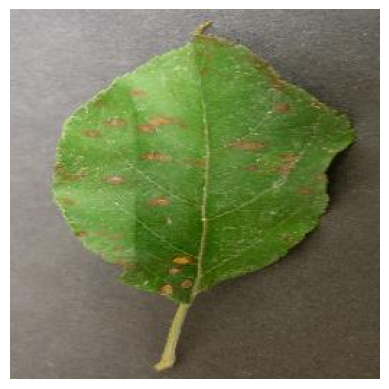

In [9]:


image_path = '/content/plantvillage dataset/color/Apple___Cedar_apple_rust/025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust 3655.JPG'

# Read the image
img = mpimg.imread(image_path)

print(img.shape)
# Display the image
plt.imshow(img)
plt.axis('off')  # Turn off axis numbers
plt.show()

In [10]:
#Img params
img_size = 224 #shape should remain same
batch_size = 32

Train-Test Split

In [11]:
data_gen = ImageDataGenerator( rescale = 1/255, validation_split=0.2)

In [12]:
#Train Generetor

train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode = 'categorical'
)

Found 43456 images belonging to 38 classes.


In [13]:
#Validation Generetor

validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode = 'categorical'
)

Found 10849 images belonging to 38 classes.


CNN

In [14]:
model  = models.Sequential()


input_shape = (224, 224, 3)
n_classes = len(train_generator.class_indices)

model.add(layers.Conv2D(filters=64, kernel_size=(7, 7), strides=(3, 3), activation='relu', input_shape=input_shape))
model.add(layers.MaxPool2D(pool_size=(3, 3)))

model.add(layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))


model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(256, activation='relu'))

model.add(layers.Dropout(0.5))

model.add(layers.Dense(n_classes, activation='softmax'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 73, 73, 64)     │         9,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,257,510 (4.80 MB)

 Trainable params: 1,257,510 (4.80 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(optimizer='adam', loss= 'categorical_crossentropy', metrics=['accuracy'])

In [17]:

history = model.fit(
    train_generator,
    batch_size=32,
    validation_data=validation_generator,
    epochs=30
)

Epoch 1/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 150s 102ms/step - accuracy: 0.4187 - loss: 2.1063 - val_accuracy: 0.7041 - val_loss: 0.9885
Epoch 2/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 122s 90ms/step - accuracy: 0.7671 - loss: 0.7707 - val_accuracy: 0.8292 - val_loss: 0.5559
Epoch 3/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 116s 86ms/step - accuracy: 0.8518 - loss: 0.4819 - val_accuracy: 0.8872 - val_loss: 0.3533
Epoch 4/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 139s 103ms/step - accuracy: 0.8916 - loss: 0.3504 - val_accuracy: 0.8499 - val_loss: 0.5089
Epoch 5/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 130s 96ms/step - accuracy: 0.9132 - loss: 0.2787 - val_accuracy: 0.9060 - val_loss: 0.3059
Epoch 6/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 125s 92ms/step - accuracy: 0.9292 - loss: 0.2316 - val_accuracy: 0.8978 - val_loss: 0.3478
Epoch 7/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 117s 86ms/step - accuracy: 0.9375 - loss: 0.2018 - val_accuracy: 0.9312 - val_loss: 0.2244
Epoch 8/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - accuracy

In [18]:

# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_generator, steps=validation_generator.samples // batch_size)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")


Evaluating model...
339/339 ━━━━━━━━━━━━━━━━━━━━ 23s 68ms/step - accuracy: 0.9317 - loss: 0.3939
Validation Accuracy: 93.17%


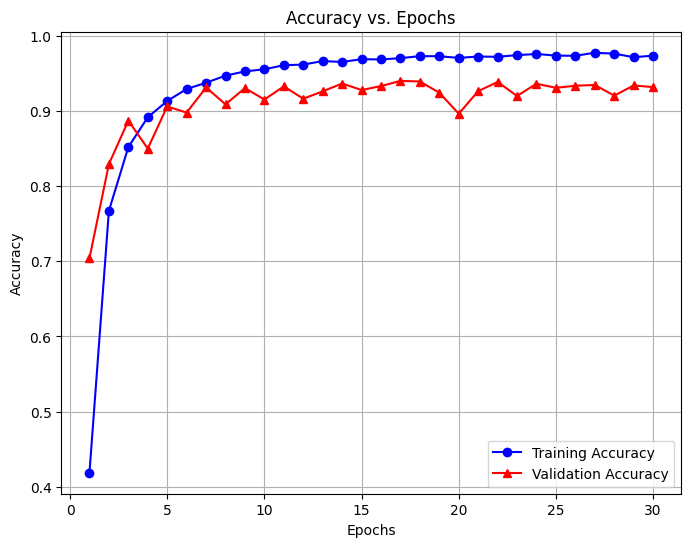

In [19]:
import matplotlib.pyplot as plt

# Extract Accuracy and Validation Accuracy from history
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(train_acc) + 1)  # Number of epochs

# Plot Training and Validation Accura cy
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_acc, 'bo-', label='Training Accuracy')  # 'bo-' means blue circles with lines
plt.plot(epochs, val_acc, 'r^-', label='Validation Accuracy')  # 'r^-' means red triangles with lines

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Epochs')
plt.legend()
plt.grid(True)
plt.show()

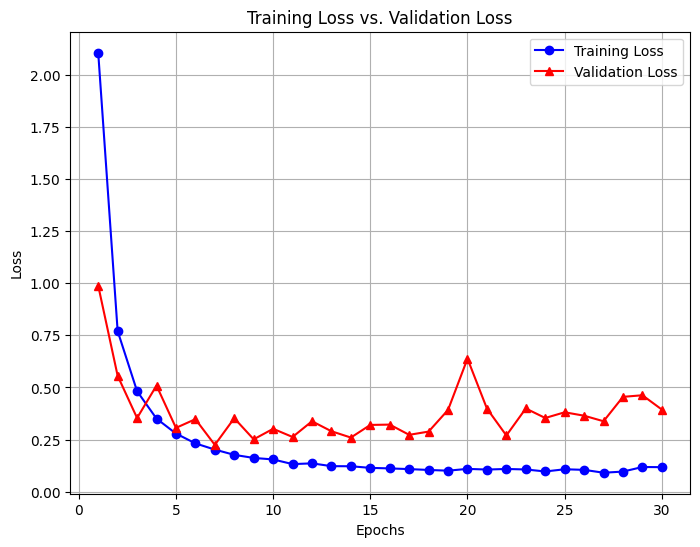

In [20]:
import matplotlib.pyplot as plt

# Extract Loss and Validation Loss from training history
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)  # Number of epochs

# Plot Training and Validation Loss
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_loss, 'bo-', label='Training Loss')  # 'bo-' means blue circles with lines
plt.plot(epochs, val_loss, 'r^-', label='Validation Loss')  # 'r^-' means red triangles with lines

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs. Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
# Function to Load and Preprocess the Image using Pillow
def load_and_preprocess_image(image_path, target_size=(224, 224)):
    # Load the image
    img = Image.open(image_path)
    # Resize the image
    img = img.resize(target_size)
    # Convert the image to a numpy array
    img_array = np.array(img)
    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)
    # Scale the image values to [0, 1]
    img_array = img_array.astype('float32') / 255.
    return img_array

# Function to Predict the Class of an Image
def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name

In [23]:

# Create a mapping from class indices to class names
class_indices = {v: k for k, v in train_generator.class_indices.items()}


class_indices

{0: 'Apple___Apple_scab',
 1: 'Apple___Black_rot',
 2: 'Apple___Cedar_apple_rust',
 3: 'Apple___healthy',
 4: 'Blueberry___healthy',
 5: 'Cherry_(including_sour)___Powdery_mildew',
 6: 'Cherry_(including_sour)___healthy',
 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 8: 'Corn_(maize)___Common_rust_',
 9: 'Corn_(maize)___Northern_Leaf_Blight',
 10: 'Corn_(maize)___healthy',
 11: 'Grape___Black_rot',
 12: 'Grape___Esca_(Black_Measles)',
 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 14: 'Grape___healthy',
 15: 'Orange___Haunglongbing_(Citrus_greening)',
 16: 'Peach___Bacterial_spot',
 17: 'Peach___healthy',
 18: 'Pepper,_bell___Bacterial_spot',
 19: 'Pepper,_bell___healthy',
 20: 'Potato___Early_blight',
 21: 'Potato___Late_blight',
 22: 'Potato___healthy',
 23: 'Raspberry___healthy',
 24: 'Soybean___healthy',
 25: 'Squash___Powdery_mildew',
 26: 'Strawberry___Leaf_scorch',
 27: 'Strawberry___healthy',
 28: 'Tomato___Bacterial_spot',
 29: 'Tomato___Early_blight',
 30: '

In [26]:

# saving the class names as json file
json.dump(class_indices, open('class_indices.json', 'w'))


# Example Usage
image_path = '/content/test_apple_black_rot.JPG'

predicted_class_name = predict_image_class(model, image_path, class_indices)
# Output the result
print("Predicted Class Name:", predicted_class_name)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Class Name: Apple___Black_rot


In [28]:

model.save('drive/MyDrive/NN/trained_models/plant_disease_prediction_model.h5')

model.save('plant_disease_prediction_model.h5')